<!-- colab-badge -->
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RemusTeodorescu/DL-for-Engineers-Public-Course/blob/main/miniprojects/MP8.2A/MP8.2A_02_reference.ipynb)

*Open this notebook in Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU). Its first code cell fetches the library files from the public course repository.*

<!-- course-header v3 -->

**Deep Learning for Engineering** · MSc, Aalborg University · 2026

Developed by **Remus Teodorescu** (ret@et.aau.dk), with support from Research Assistant **Noman Khan** (nomank@energy.aau.dk).

*Reference texts — read for the theory. Used as an **inspirational source** for this course, not as a source of its code:*

- Liu, *PINN with Python*, 2025.
- Raissi, Perdikaris & Karniadakis, *Physics-informed neural networks*, J. Comput. Phys. 378 (2019) 686–707.
- Prince, *Understanding Deep Learning*, MIT Press 2023.

Every notebook in this course has been **written and rewritten by the authors named above**. The code, the problems, the data and the exposition are **original to this course** and are not derived from any publisher's code listings or companion notebooks. Where notation matches a textbook's it is the standard notation of the field, and where an idea is a named author's it is cited as theirs in the text.

See `docs/PROVENANCE.md` for what each reference is cited for, set by set.

---

# MP8.2A · Thermal Cycling with Natural Convection
## 02 · The Reference Model and the Ground Truth

*Mini project of the course **Deep Learning for Engineering**, Part 2. Five notebooks, run in order:*

00 The Problem → 01 The Data and the Physics → **02 The Reference Model and the Ground Truth** → 03 The Physics-Informed Network → 04 The Report

*Notebooks 00 to 02 are given and solved: read them, run them, and use what they build. Notebooks 03 and 04 are yours.*

In [1]:
# files-cell (mini project) ----------------------------------------------------
# The library files must sit beside the notebook. Locally they already do. On
# Google Colab they are fetched from the public course repository on every
# run, so a file left over from an earlier session cannot shadow it.
import os, sys, urllib.request
EXERCISE = (['course_core.py', 'pinn_core.py', 'heatsink.py'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/exercises/Ex08-heatsink-cooling/")
PROJECT = (['mp82a.py', 'MP8.2A_truth.npz'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/miniprojects/MP8.2A/")
ON_COLAB = "google.colab" in sys.modules
for files, url in (EXERCISE, PROJECT):
    for f in files:
        if ON_COLAB or not os.path.exists(f):
            if not ON_COLAB and os.path.exists(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f)):
                import shutil; shutil.copy(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f), f)
            else:
                urllib.request.urlretrieve(url + f, f)
            print("fetched", f)
for _m in ['course_core', 'pinn_core', 'heatsink', 'mp82a']:
    sys.modules.pop(_m, None)
print("files ready")

files ready


In [2]:
# --- setup ---------------------------------------------------------------
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import course_core as cc
import heatsink as hs
import mp82a as mp
torch.set_default_dtype(torch.float64)                   # a second derivative of a network needs double precision
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # the GPU, when the runtime has one
cc.keep_outputs("MP8.2A_outputs")                            # results kept between the notebooks (Google Drive on Colab)
print("device:", DEVICE, "| torch", torch.__version__)

def middle(fn, reps=5):
    """The middle of five wall-clock timings of fn(), after one warm-up run;
    on a GPU, synchronised so the time is the computation's, not the launch's."""
    sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)
    fn(); sync(); ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); sync(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

device: cpu | torch 2.14.1+cu130


## 1 · Two solvers, two jobs

| | the **reference model** | the **ground truth** |
|---|---|---|
| what it is | the solver an engineer would run: finite differences on an engineering grid | the same scheme on a grid fine enough to be ten to a hundred times more exact than anything scored |
| grid | 11 × 3 nodes, a step of 4 s | 161 × 33 nodes, a step of 0.125 s |
| its job | to be **timed** against the network: the online cost of answering a new power | to **score** the network and the reference |

Both march the same discrete equations, written in `mp82a.March`. The rest of this notebook explains the scheme, builds confidence in the ground truth, and measures the reference model's accuracy and time - the bar notebook 03 has to clear.

## 2 · The scheme, step by step

1. **Nodes.** A grid of $n_x \times n_z$ nodes covers the base plate, edges included.
2. **Conduction.** At every node the second derivatives are central differences of its neighbours, $(\theta_{i+1} - 2\theta_i + \theta_{i-1})/h^2$.
3. **Conditions by ghost nodes.** A condition on a slope is met by imagining a node one step outside the plate and choosing its value so that the central difference of the slope is what the condition asks. At the insulated ends the ghost mirrors its neighbour. At the module face it carries the flux. At the fin side it carries $h_\mathrm{eff}(\theta)\,\theta$, which depends on the node's own value.
4. **Time: Crank-Nicolson.** Each step averages the right-hand side over the start and the end of the step, which is second-order accurate and stable for any step. It needs one sparse linear solve per step, with a matrix factorised once.
5. **The nonlinear fin side: chord iterations.** The fin term is evaluated at the end of the step, where the value is not yet known. Each step therefore solves three times, each time with the fin term evaluated at the last estimate, using the matrix factorised once with the fin side linearised at a 20 K rise. Three iterations converge to rounding; ten change nothing.
6. **After a switch: Rannacher's start.** When the flux jumps, Crank-Nicolson carries the jump forward as an undamped oscillation and loses its second order. The two steps after every switch are therefore taken as backward-Euler half steps, which damp it. Without them the error falls only by a factor of 2.3 per refinement instead of 4.

`mp.March(nx, nz, dt).run(P)` returns the times, the centre's rise at every step, and the fields at chosen instants.

In [3]:
# The ground truth: its convergence study at 150 W, from the truth file
G = np.load("MP8.2A_truth.npz")
print("grid (nx × nz, dt)        peak of cycle 10   trough of cycle 10")
for g, p, q in zip(G["conv_grids"], G["conv_peak10"], G["conv_trough10"]):
    print(f"{int(g[0]):4d} × {int(g[1]):3d}, {g[2]:.4f} s      {p:10.4f} K       {q:10.4f} K")
d = np.abs(np.diff(G["conv_peak10"]))
print("change between grids:", np.round(d, 4), "K;  ratios", np.round(d[:-1] / d[1:], 1))
print(f"Richardson extrapolation: {float(G['conv_peak10_extrapolated']):.4f} K")
print(f"at S = 0, the march against Ex08's exact series: {float(G['zero_strength_error_K']):.4f} K at most")

grid (nx × nz, dt)        peak of cycle 10   trough of cycle 10
  41 ×   9, 0.5000 s         23.3915 K           9.9919 K
  81 ×  17, 0.2500 s         23.3952 K           9.9918 K
 161 ×  33, 0.1250 s         23.3961 K           9.9918 K
 321 ×  65, 0.0625 s         23.3963 K           9.9918 K
change between grids: [0.0037 0.0009 0.0002] K;  ratios [4. 4.]
Richardson extrapolation: 23.3964 K
at S = 0, the march against Ex08's exact series: 0.0006 K at most


**What you should see.** Four grids, each twice as fine in $x$, $z$ and $t$. The change of the tenth peak between grids falls by about four each time - the second order of the scheme. The ground truth's grid (161 × 33) is within 0.001 K of the extrapolated value, three hundred times finer than the 0.3 K asked. At $S = 0$ the same march reproduces Ex08's exact series to better than 0.001 K: the code is right where the answer is known.

In [4]:
# The energy balance over the window, on three grids
for g in [(11, 3, 4.0), (41, 9, 0.5), (161, 33, 0.125)]:
    m = mp.March(*g); m.run(150.0)
    b = m.balance
    print(f"{g[0]:4d} × {g[1]:3d}: heat in {b['heat_in']:8.1f} J = through the fins {b['heat_out']:8.1f} J "
          f"+ stored {b['stored']:7.1f} J;  off by {abs(b['residual'])/b['heat_in']:.1e} of the heat in")

  11 ×   3: heat in  30000.0 J = through the fins  27548.7 J + stored  2417.6 J;  off by 1.1e-03 of the heat in


  41 ×   9: heat in  30000.0 J = through the fins  27580.2 J + stored  2419.2 J;  off by 1.8e-05 of the heat in


 161 ×  33: heat in  30000.0 J = through the fins  27580.7 J + stored  2419.3 J;  off by 1.2e-06 of the heat in


**What you should see.** 30 000 J in over the ten pulses; about 27 580 J through the fins and 2 420 J still stored in the base at 600 s; the balance closes to $10^{-3}$ on the coarse grid and $10^{-6}$ on the ground truth's.

## 3 · The reference model: accuracy and time

The reference grid was chosen as the coarsest that meets the agreed 0.3 K on every peak and trough at the test powers. The cell below scores it against the ground truth and times it. It runs on the CPU of the Colab runtime: a small sparse march gains nothing from a GPU, and an engineer would not run it on one.

In [5]:
# The reference model against the ground truth, at the three test powers
worst = 0.0
for P in mp.P_TEST:
    r = mp.reference(P)
    key = f"{int(P)}W"
    e = max(np.abs(r["peaks"] - G["peaks_" + key]).max(), np.abs(r["troughs"] - G["troughs_" + key]).max())
    worst = max(worst, e)
    print(f"P = {P:.0f} W: peak of cycle 10 {r['peaks'][-1]:.2f} K (truth {G['peaks_' + key][-1]:.2f}),"
          f" worst peak or trough off by {e:.2f} K")
t_ref = middle(lambda: mp.reference(165.0))              # the online cost of a new power
print(f"\nreference model: worst {worst:.2f} K, {t_ref*1e3:.1f} ms per new power")
print(f"the network must answer a new power in under {t_ref*1e3/10:.2f} ms (ten times shorter)")
import json
path = cc.output_path("MP8.2A_reference.json")
with open(path, "w") as fh:
    json.dump({"t_ref_s": t_ref, "worst_ref_K": worst}, fh)
cc.saved(path)                                           # kept in Drive (or downloaded) for notebook 04

P = 115 W: peak of cycle 10 18.14 K (truth 18.02), worst peak or trough off by 0.12 K
P = 165 W: peak of cycle 10 25.87 K (truth 25.69), worst peak or trough off by 0.18 K
P = 195 W: peak of cycle 10 30.49 K (truth 30.28), worst peak or trough off by 0.21 K



reference model: worst 0.21 K, 31.2 ms per new power
the network must answer a new power in under 3.12 ms (ten times shorter)
saved: MP8.2A_outputs/MP8.2A_reference.json


**What you should see.** At every test power the reference model's peaks and troughs are within about 0.21 K of the ground truth, inside the 0.3 K agreed. One run takes some tens of milliseconds (26 to 55 ms on the authors' CPUs), almost all of it the 150 steps of the march. Its time is saved for notebook 04, which compares the network against it on this same runtime.

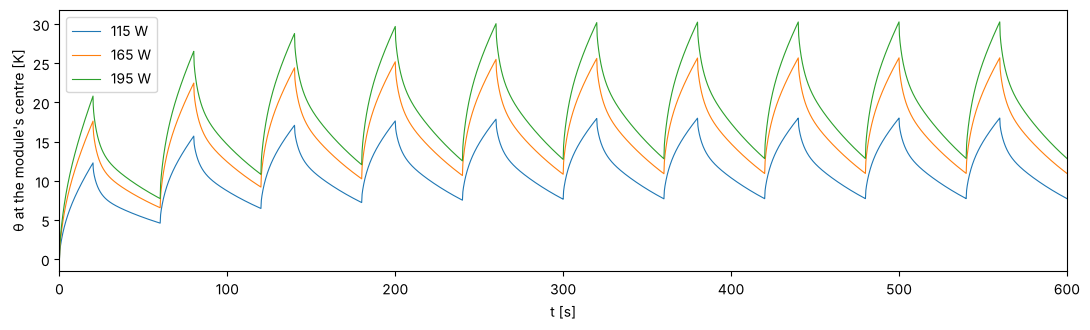

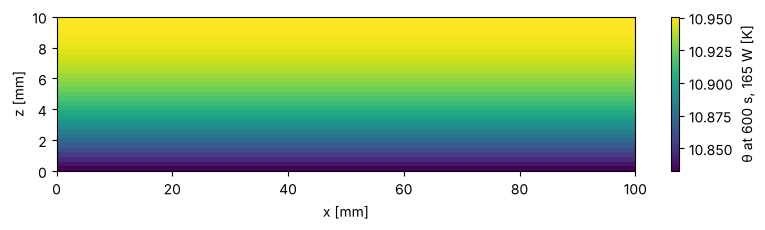

In [6]:
# The ground truth's history at the three test powers, the target of notebook 03
fig, ax = plt.subplots(figsize=(11, 3.4))
for P in mp.P_TEST:
    ax.plot(G["t"], G[f"centre_{int(P)}W"], lw=0.8, label=f"{P:.0f} W")
ax.set_xlabel("t [s]"); ax.set_ylabel("θ at the module's centre [K]"); ax.set_xlim(0, mp.T_END); ax.legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 2.4))
im = ax.imshow(G["field_165W"], origin="lower", aspect="auto", extent=[0, hs.W_BASE*1e3, 0, hs.T_BASE*1e3])
ax.set_xlabel("x [mm]"); ax.set_ylabel("z [mm]"); plt.colorbar(im, label="θ at 600 s, 165 W [K]")
plt.tight_layout(); plt.show()

**What you should see.** Three saw-tooth histories, higher with the power but not in proportion to it - natural convection cools a hotter sink better. Below, the field at the end of the window at 165 W: hottest under the module, cooler towards the ends, the fin side a few kelvin below the module side. These are what notebook 03's network must reproduce.